# Лабораторна робота №1. Класифікація фішингових сайтів

Датасет Phishing Dataset for Machine Learning (Kaggle), https://www.kaggle.com/datasets/shashwatwork/phishing-dataset-for-machine-learning

Задача полягає в тому, щоб за ознаками URL і HTML-сторінки визначити, чи сайт фішинговий (CLASS_LABEL = 1) чи легітимний (CLASS_LABEL = 0).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

## 1. Завантаження та первинний аналіз даних

In [2]:
df = pd.read_csv('../../data/phishing_ml/Phishing_Legitimate_full.csv')

In [3]:
df.head()

,id,NumDots,SubdomainLevel,PathLevel,UrlLength,NumDash,NumDashInHostname,AtSymbol,TildeSymbol,NumUnderscore,...,IframeOrFrame,MissingTitle,ImagesOnlyInForm,SubdomainLevelRT,UrlLengthRT,PctExtResourceUrlsRT,AbnormalExtFormActionR,ExtMetaScriptLinkRT,PctExtNullSelfRedirectHyperlinksRT,CLASS_LABEL
0,1,3,1,5,72,0,0,0,0,0,...,0,0,1,1,0,1,1,-1,1,1
1,2,3,1,3,144,0,0,0,0,2,...,0,0,0,1,-1,1,1,1,1,1
2,3,3,1,2,58,0,0,0,0,0,...,0,0,0,1,0,-1,1,-1,0,1
3,4,3,1,6,79,1,0,0,0,0,...,0,0,0,1,-1,1,1,1,-1,1
4,5,3,0,4,46,0,0,0,0,0,...,1,0,0,1,1,-1,0,-1,-1,1


In [4]:
df.shape  # рядки і стовпці

(10000, 50)

In [5]:
df.columns

Index(['id', 'NumDots', 'SubdomainLevel', 'PathLevel', 'UrlLength', 'NumDash',
       'NumDashInHostname', 'AtSymbol', 'TildeSymbol', 'NumUnderscore',
       'NumPercent', 'NumQueryComponents', 'NumAmpersand', 'NumHash',
       'NumNumericChars', 'NoHttps', 'RandomString', 'IpAddress',
       'DomainInSubdomains', 'DomainInPaths', 'HttpsInHostname',
       'HostnameLength', 'PathLength', 'QueryLength', 'DoubleSlashInPath',
       'NumSensitiveWords', 'EmbeddedBrandName', 'PctExtHyperlinks',
       'PctExtResourceUrls', 'ExtFavicon', 'InsecureForms',
       'RelativeFormAction', 'ExtFormAction', 'AbnormalFormAction',
       'PctNullSelfRedirectHyperlinks', 'FrequentDomainNameMismatch',
       'FakeLinkInStatusBar', 'RightClickDisabled', 'PopUpWindow',
       'SubmitInfoToEmail', 'IframeOrFrame', 'MissingTitle',
       'ImagesOnlyInForm', 'SubdomainLevelRT', 'UrlLengthRT',
       'PctExtResourceUrlsRT', 'AbnormalExtFormActionR', 'ExtMetaScriptLinkRT',
       'PctExtNullSelfRedirectHyperl

In [6]:
df.dtypes

id                                      int64
NumDots                                 int64
SubdomainLevel                          int64
PathLevel                               int64
UrlLength                               int64
NumDash                                 int64
NumDashInHostname                       int64
AtSymbol                                int64
TildeSymbol                             int64
NumUnderscore                           int64
NumPercent                              int64
NumQueryComponents                      int64
NumAmpersand                            int64
NumHash                                 int64
NumNumericChars                         int64
NoHttps                                 int64
RandomString                            int64
IpAddress                               int64
DomainInSubdomains                      int64
DomainInPaths                           int64
HttpsInHostname                         int64
HostnameLength                    

In [7]:
df['CLASS_LABEL'].value_counts()  # розподіл за класами

CLASS_LABEL
1    5000
0    5000
Name: count, dtype: int64

У таблиці 10000 рядків і 50 стовпців. Цільова змінна CLASS_LABEL, класи рівні (по 5000), тобто дані збалансовані. Усі ознаки числові. Стовпець id є лише номером рядка, тому ознакою не буде.

In [8]:
X = df.drop(['id', 'CLASS_LABEL'], axis=1)  # ознаки
y = df['CLASS_LABEL']  # ціль
X.shape

(10000, 48)

## 2. Попередня обробка даних

In [9]:
df.isna().sum().sum()  # скільки пропусків усього

np.int64(0)

Пропусків немає, тому нічого не заповнюємо і не видаляємо. Категоріальних (текстових) ознак теж немає, усі стовпці числові, тому кодування не потрібне.

In [10]:
df.corr()['CLASS_LABEL'].loc['id']  # зв'язок id з ціллю

np.float64(-0.8660254081145654)

Стовпець id сильно корелює з ціллю, бо рядки в файлі впорядковані за класом. Це не властивість сайту, тому id видаляємо, інакше модель буде вгадувати клас за номером.

In [11]:
df = df.drop('id', axis=1)

In [12]:
df.duplicated().sum()  # однакові рядки

np.int64(419)

Є повністю однакові рядки. Їх видаляємо до розбиття на train і test, інакше копія одного рядка потрапить і в навчальну, і в тестову вибірку, і оцінка буде завищеною.

In [13]:
df = df.drop_duplicates()

In [14]:
df.shape

(9581, 49)

In [15]:
df['CLASS_LABEL'].value_counts()

CLASS_LABEL
0    4996
1    4585
Name: count, dtype: int64

Після очищення лишилося 9581 рядок. Дублікати були переважно серед фішингових сайтів, тому класи тепер майже збалансовані (4996 і 4585), що для точності не критично.

In [16]:
X = df.drop('CLASS_LABEL', axis=1)
y = df['CLASS_LABEL']

## 3. Візуалізація та дослідження даних (EDA)

In [17]:
corr = df.corr()['CLASS_LABEL'].abs().sort_values(ascending=False)
top = corr.index[1:11]  # 10 ознак, найбільш пов'язаних з ціллю
top

Index(['PctExtNullSelfRedirectHyperlinksRT', 'FrequentDomainNameMismatch',
       'NumDash', 'SubmitInfoToEmail', 'PctNullSelfRedirectHyperlinks',
       'InsecureForms', 'NumDots', 'PctExtHyperlinks', 'NumSensitiveWords',
       'IframeOrFrame'],
      dtype='str')

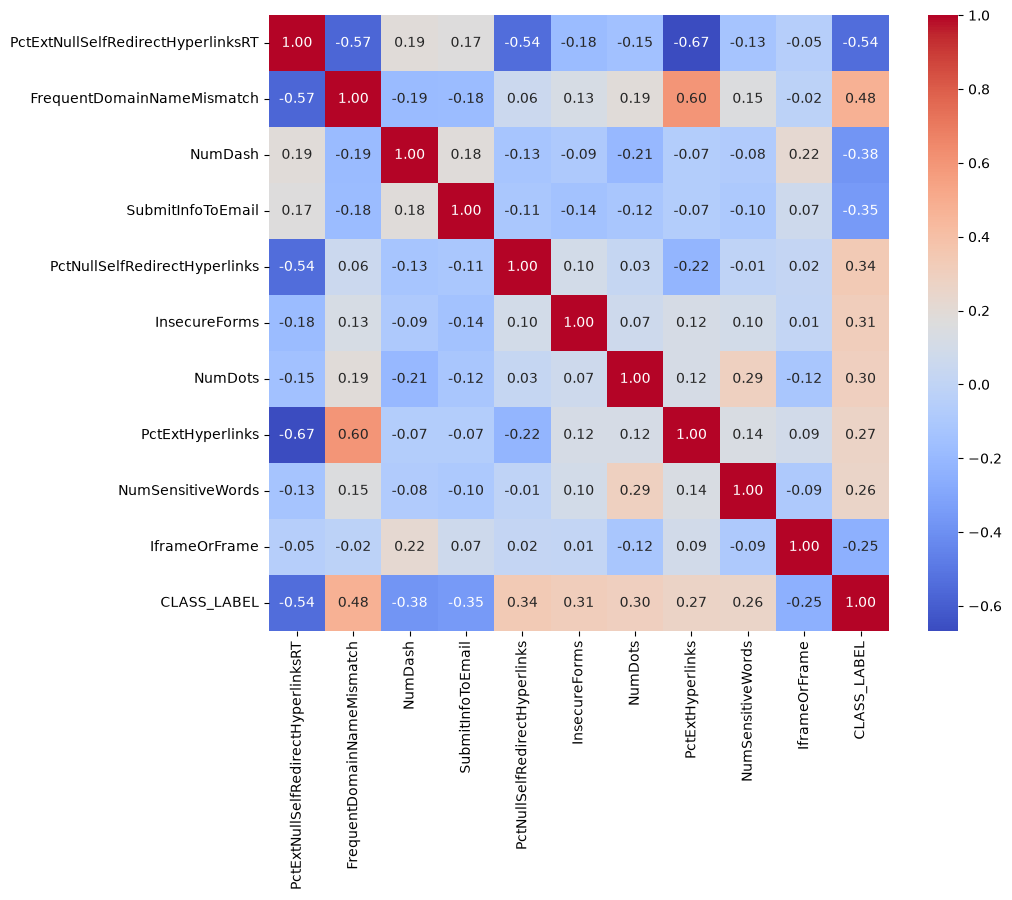

In [18]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[list(top) + ['CLASS_LABEL']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

Показано 10 ознак, найбільш пов'язаних з ціллю (усі 48 на одному рисунку нечитабельні). Найсильніший зв'язок з CLASS_LABEL мають PctExtNullSelfRedirectHyperlinksRT (-0,54) і FrequentDomainNameMismatch (0,48), решта в межах від -0,38 до 0,34. Жодна ознака окремо клас не визначає, а деякі пов'язані між собою (PctExtHyperlinks і PctExtNullSelfRedirectHyperlinksRT мають -0,67).

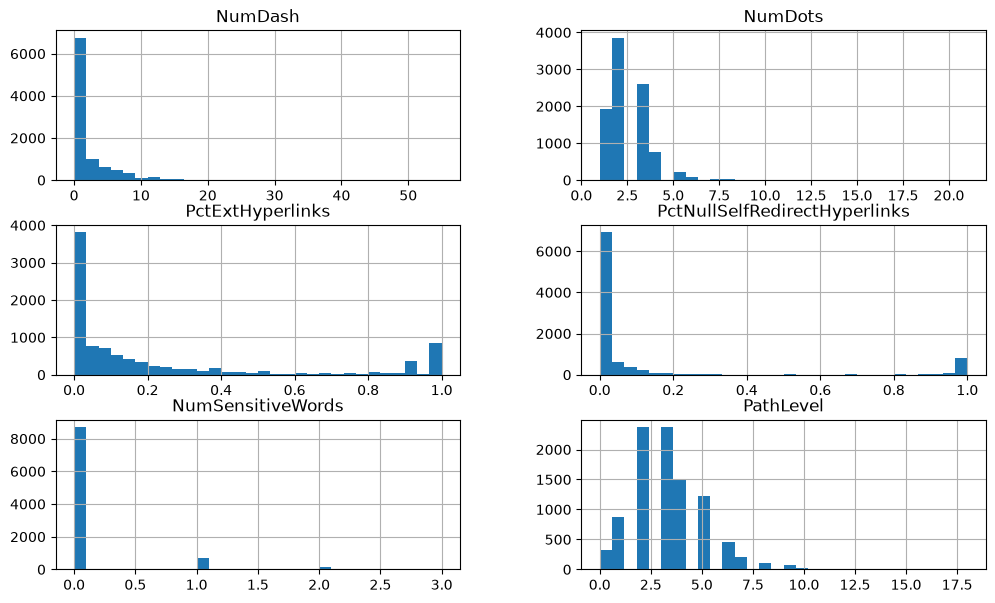

In [19]:
features = ['NumDash', 'NumDots', 'PctExtHyperlinks', 'PctNullSelfRedirectHyperlinks', 'NumSensitiveWords', 'PathLevel']
df[features].hist(bins=30, figsize=(12, 7))
plt.show()

Більшість розподілів зміщені до малих значень, а в NumDash, NumDots і PathLevel є довгий правий хвіст. NumSensitiveWords майже завжди дорівнює нулю. Ознаки мають різні масштаби, тому для kNN і SVM знадобиться масштабування.

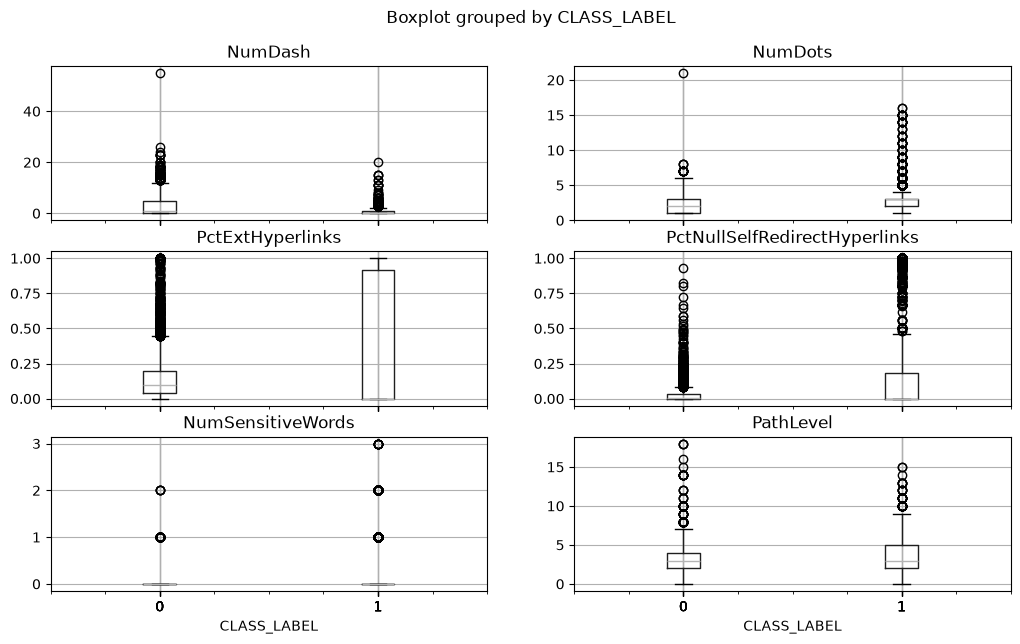

In [20]:
df.boxplot(column=features, by='CLASS_LABEL', figsize=(12, 7), sharey=False)
plt.show()

Для фішингових сайтів (клас 1) типово менше дефісів в URL, трохи більше крапок і значно вищі частки зовнішніх посилань (PctExtHyperlinks) та посилань без переходу. У NumSensitiveWords і PathLevel медіани однакові, розрізняються лише викиди. Діапазони класів перекриваються, тому жодна ознака окремо не розділяє класи.

## 4. Підготовка даних до навчання

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [22]:
X_train.shape, X_test.shape

((7664, 48), (1917, 48))

In [23]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # fit лише на train
X_test_scaled = scaler.transform(X_test)

Розбиття 80 на 20 зі збереженням пропорції класів (stratify). Масштабування потрібне kNN і SVM, бо вони працюють з відстанями, і ознака з великими числами (наприклад UrlLength) заглушила б решту. Параметри масштабування обчислено лише на train, щоб тест лишався незалежним. Дерева, Random Forest і AdaBoost порівнюють значення одної ознаки з порогом, тому масштаб їм не важливий і вони працюють з немасштабованими даними.

## 5. Навчання моделей

In [24]:
knn = KNeighborsClassifier()
knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [25]:
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [26]:
svm = SVC(random_state=42)
svm.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [27]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [28]:
ada = AdaBoostClassifier(random_state=42)
ada.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](50,)","[0.23,0.2 ,0.21,...,0.48,0.48,0.44]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](50,)","[1.23,1.37,1.31,...,0.07,0.08,0.26]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1608637542), DecisionTreeC...te=1273642419), DecisionTreeC...te=1935803228), DecisionTreeC...ate=787846414), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](48,)","[0.02,0. ,0.07,...,0. ,0.04,0.12]"


Усі п'ять моделей навчено з параметрами за замовчуванням. Далі підберемо гіперпараметри для kNN і SVM.

## 6. Підбір гіперпараметрів

Підбір ведемо на тренувальних даних за 5-кратною крос-валідацією, тест у цьому не бере участі.

In [29]:
knn_grid = GridSearchCV(KNeighborsClassifier(), {'n_neighbors': range(1, 31)}, cv=5)
knn_grid.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_neighbors': range(1, 31)}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with higherva

In [30]:
knn_grid.best_params_, knn_grid.best_score_

({'n_neighbors': 1}, np.float64(0.9545926092458513))

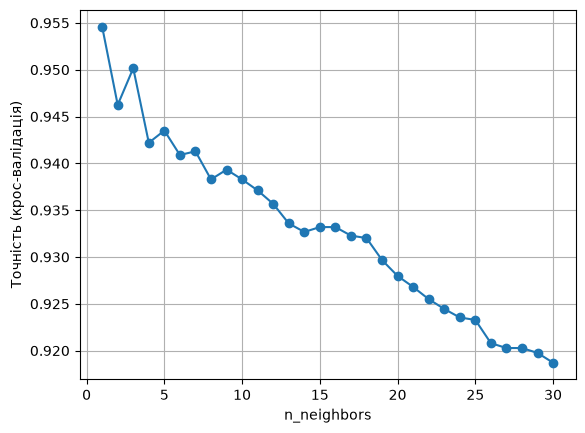

In [31]:
plt.plot(range(1, 31), knn_grid.cv_results_['mean_test_score'], marker='o')
plt.xlabel('n_neighbors')
plt.ylabel('Точність (крос-валідація)')
plt.grid()
plt.show()

Точність у середньому падає зі зростанням k, найкраще значення k = 1, а k = 3 майже таке саме. Імовірно, у даних є дуже схожі сторінки (наприклад з одного сайту), для яких найближчий сусід майже завжди має правильний клас, а більше сусідів лише розмиває результат.

In [32]:
svm_params = {'C': [0.1, 1, 10, 100], 'gamma': ['scale', 0.001, 0.01, 0.1]}
svm_grid = GridSearchCV(SVC(kernel='rbf', random_state=42), svm_params, cv=5)
svm_grid.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC(random_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'gamma': ['scale', 0.001, ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during f

In [33]:
svm_grid.best_params_, svm_grid.best_score_

({'C': 10, 'gamma': 'scale'}, np.float64(0.9703805231810525))

Для SVM перебрано 16 пар C і gamma. C задає штраф за помилки (більше C дає складнішу межу), gamma задає радіус впливу одного об'єкта.

In [34]:
knn_best = knn_grid.best_estimator_
svm_best = svm_grid.best_estimator_

## 7. Порівняння та оцінювання моделей

In [35]:
pred_knn = knn_best.predict(X_test_scaled)
pred_tree = tree.predict(X_test)
pred_svm = svm_best.predict(X_test_scaled)
pred_rf = rf.predict(X_test)
pred_ada = ada.predict(X_test)

### kNN

In [36]:
print(classification_report(y_test, pred_knn))
confusion_matrix(y_test, pred_knn)

              precision    recall  f1-score   support

           0       0.95      0.94      0.95      1000
           1       0.94      0.95      0.94       917

    accuracy                           0.95      1917
   macro avg       0.94      0.95      0.95      1917
weighted avg       0.95      0.95      0.95      1917



array([[940,  60],
       [ 45, 872]])

### Decision Tree

In [37]:
print(classification_report(y_test, pred_tree))
confusion_matrix(y_test, pred_tree)

              precision    recall  f1-score   support

           0       0.98      0.97      0.97      1000
           1       0.96      0.97      0.97       917

    accuracy                           0.97      1917
   macro avg       0.97      0.97      0.97      1917
weighted avg       0.97      0.97      0.97      1917



array([[966,  34],
       [ 23, 894]])

### SVM

In [38]:
print(classification_report(y_test, pred_svm))
confusion_matrix(y_test, pred_svm)

              precision    recall  f1-score   support

           0       0.98      0.97      0.98      1000
           1       0.97      0.97      0.97       917

    accuracy                           0.97      1917
   macro avg       0.97      0.97      0.97      1917
weighted avg       0.97      0.97      0.97      1917



array([[974,  26],
       [ 23, 894]])

### Random Forest

In [39]:
print(classification_report(y_test, pred_rf))
confusion_matrix(y_test, pred_rf)

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1000
           1       0.99      0.99      0.99       917

    accuracy                           0.99      1917
   macro avg       0.99      0.99      0.99      1917
weighted avg       0.99      0.99      0.99      1917



array([[989,  11],
       [ 12, 905]])

### AdaBoost

In [40]:
print(classification_report(y_test, pred_ada))
confusion_matrix(y_test, pred_ada)

              precision    recall  f1-score   support

           0       0.98      0.95      0.96      1000
           1       0.95      0.97      0.96       917

    accuracy                           0.96      1917
   macro avg       0.96      0.96      0.96      1917
weighted avg       0.96      0.96      0.96      1917



array([[954,  46],
       [ 24, 893]])

### Підсумкова таблиця

In [41]:
results = pd.DataFrame({
    'model': ['kNN', 'Decision Tree', 'SVM', 'Random Forest', 'AdaBoost'],
    'accuracy': [accuracy_score(y_test, p) for p in [pred_knn, pred_tree, pred_svm, pred_rf, pred_ada]],
    'precision': [precision_score(y_test, p) for p in [pred_knn, pred_tree, pred_svm, pred_rf, pred_ada]],
    'recall': [recall_score(y_test, p) for p in [pred_knn, pred_tree, pred_svm, pred_rf, pred_ada]],
    'f1': [f1_score(y_test, p) for p in [pred_knn, pred_tree, pred_svm, pred_rf, pred_ada]]})
results.round(4)

,model,accuracy,precision,recall,f1
0,kNN,0.9452,0.9356,0.9509,0.9432
1,Decision Tree,0.9703,0.9634,0.9749,0.9691
2,SVM,0.9744,0.9717,0.9749,0.9733
3,Random Forest,0.9880,0.9880,0.9869,0.9875
4,AdaBoost,0.9635,0.9510,0.9738,0.9623


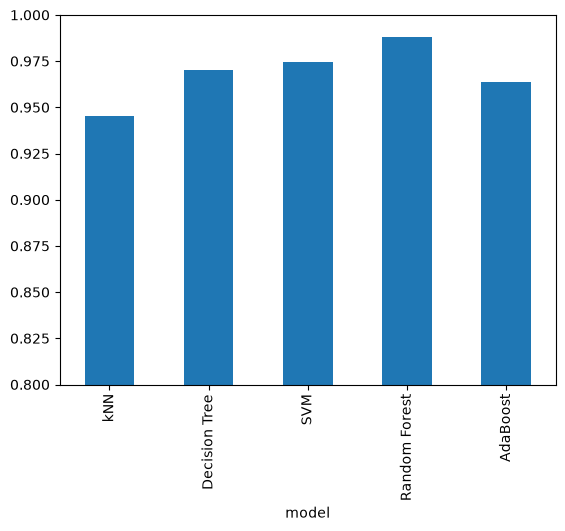

In [42]:
results.plot.bar(x='model', y='accuracy', ylim=(0.8, 1.0), legend=False)
plt.show()

### Висновок

Найкращий результат на тесті має Random Forest (accuracy 0,988, помилилися лише 23 об'єкти з 1917). Він випереджає SVM (0,974) приблизно на 1,4 п.п., тобто на 26 об'єктів, що більше за статистичний розкид оцінки на такій вибірці. SVM і Decision Tree (0,970) практично однакові. AdaBoost (0,964) трохи слабший, kNN (0,945) найгірший. Random Forest краще підходить для цих даних, бо ознаки різнорідні (лічильники, частки, бінарні прапорці з різними масштабами), а ансамбль дерев добре ловить нелінійні взаємодії між ними і сильно менше перенавчається, ніж одне дерево. Усі метрики для обох класів (precision, recall, f1) у кожної моделі близькі, тому перекосу в бік одного класу немає.